# 234. FUN Botryllus proteome: matches to human immune genes and HLA, with the 19 kmerseek alphabets of notebook 233

**Question.** [Notebook 233](233_kmerseek_botryllus_immune_hla_19_alphabets.ipynb) searched the
old Botryllus proteome (72,617 translations, `Bs_proteins.fa`) with 19 kmerseek alphabets and
found no MHC-like candidate. Does the new proteome, 45,339 FUN proteins from funannotate, give
a Botryllus protein matching an HLA groove or Ig-like domain? A protein missing or broken in
the old gene models could be whole in the new ones.

**Decision this informs.** Whether the "no MHC-like candidate from kmerseek" verdict of
notebooks 232 and 233 holds for the new gene models, or whether a FUN protein goes forward
to structure comparison.

**Decision rule, written before looking at the results** (the same as notebooks 232 and 233).

* A Botryllus protein is an MHC-like candidate if, in any alphabet, it matches an HLA gene at
  E ≤ 0.001 and the matched part of the HLA protein is the peptide-binding groove (class I
  α1/α2, class II α1/β1) or the Ig-like domain.
* HLA matches with E between 0.001 and 10 are listed but treated as chance. Agreement
  between alphabets is not evidence on its own: the alphabets read the same residues.
* A match only to the HLA transmembrane helix or signal peptide is not MHC evidence.

**Data.**

* Tool: kmerseek 0.4.0, the alphabets, k, mismatch penalties and X-drops of notebook 233
  (`233_arms.tsv`: each alphabet's k carries at least the 24.0 bits of `hp_lehninger2` at
  k = 24; protein20 runs at k = 6). Scaled = 1, low-complexity k-mers removed.
* Query: 45,339 FUN Botryllus proteins (`botryllus_new_genome_protein.fasta`, 23 Oct 2026),
  cleaned by `234_prepare_fun_proteome.py`: 2,019 IDs that appear 2 to 6 times with
  different sequences get `-T1`, `-T2`, ... ; 10 commas in names become `-`; one `.` in a
  sequence becomes `X`. Every change is in `234_outputs/234_fun_proteome_renamed_headers.tsv`.
  17,455 FUN names carry a gene name from funannotate (`FUN000002_NLRC5`).
* Target database: 19,429 human GENCODE v49 canonical proteins, as in notebook 233.
* Run: Sherlock, 27 Oct 2026 (`234_submit_fun_proteome.sh`: arrays 49810652 and 49810657).
  Matches kept as in notebook 233: E ≤ 10 or E = inf, then only those to human immune genes
  (QuickGO GO:0002376 and the terms below it). HLA protein parts come from UniProt
  (`hla_utils.py`).
* E = inf: kmerseek found shared k-mers but did not extend them into an alignment, so no
  E-value exists. These are reported in section 5.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import pubfig as pf
from hla_utils import (CLASS_I, KNOWN_IMMUNE_FAMILY_PATTERN, PART_COLOUR, PART_MARKER, HlaParts,
                       load_immune_genes, with_gene_columns)

pf.use_style()
pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_width_chars(220)
pl.Config.set_fmt_str_lengths(60)

RUN_DIR = Path.home() / "data/botryllus/kmerseek-0.4-alphabets-fun"
QUERY_TARGET_LINE = "query: FUN Botryllus proteins (45,339); target: human GENCODE v49 canonical (19,429)"
MAX_EVALUE = 10
STRICT_EVALUE = 1e-3
EVALUE_CUTOFFS = [10, 1, STRICT_EVALUE]
ZERO_X = 0.5  # where a count of 0 is drawn on a log axis, as a grey x
N_PAIRS = 45_339 * 19_429  # Botryllus proteins x human proteins: tests per alphabet
OUT_DIR = Path("234_outputs")
FIG_DIR = Path("../figures/234")
for d in (OUT_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

arms = pl.read_csv("233_arms.tsv", separator="\t")
# Alphabets grouped by class count, with a gap between groups on every figure.
GROUPS = [("2-3 classes", 2, 3), ("4-8 classes", 4, 8), ("12-18 classes", 12, 18), ("20 classes", 20, 20)]
arms = arms.with_columns(
    pl.when(pl.col("n_classes") <= 3).then(0).when(pl.col("n_classes") <= 8).then(1)
    .when(pl.col("n_classes") <= 18).then(2).otherwise(3).alias("group")
).sort("group", "n_classes", "alphabet")
# only the alphabets whose run has finished and been filtered (gbmr7 takes longest)
arms = arms.filter(pl.struct("alphabet", "ksize").map_elements(
    lambda r: (RUN_DIR / "immune" / f"{r['alphabet']}.k{r['ksize']}.scaled1.lcremoved.immune.evalue_inf.hla.csv.gz").exists(),
    return_dtype=pl.Boolean))
ALPHABETS = arms["alphabet"].to_list()
K_OF = dict(zip(arms["alphabet"], arms["ksize"]))
Y_OF, y = {}, 0
for g in range(len(GROUPS)):
    for a in arms.filter(pl.col("group") == g)["alphabet"]:
        Y_OF[a] = y
        y += 1
    y += 0.8  # gap between groups
LABEL_OF = {a: f"{a}, k = {K_OF[a]}" for a in ALPHABETS}
TOOL_LINE = f"kmerseek 0.4.0, {len(ALPHABETS)} alphabets at ≥ 24 bits per k-mer, scaled = 1, low-complexity k-mers removed"


def tag(alphabet: str) -> str:
    return f"{alphabet}.k{K_OF[alphabet]}.scaled1.lcremoved"


def with_fun_name(frame: pl.DataFrame) -> pl.DataFrame:
    """Add fun_name, the gene name funannotate gave the Botryllus protein (FUN000002_NLRC5 ->
    NLRC5; FUN000051_GALNT6-T2 -> GALNT6), null when the name is only the FUN ID."""
    name = pl.col("query_name").str.extract(r"^FUN\d+_(.+?)(?:-T\d+)?$")
    return frame.with_columns(pl.when(name.str.starts_with("FUN")).then(None).otherwise(name).alias("fun_name"))


def alphabet_axis(ax) -> None:
    """One row per alphabet, grouped by class count, a guide line from each tick."""
    ax.set_yticks([Y_OF[a] for a in ALPHABETS], [LABEL_OF[a] for a in ALPHABETS])
    for a in ALPHABETS:
        ax.axhline(Y_OF[a], color="#dddddd", linewidth=0.3, zorder=0)
    ax.set_ylim(max(Y_OF.values()) + 0.6, -0.6)


immune_genes = load_immune_genes()
missing = sorted(set(pl.read_csv("233_arms.tsv", separator="\t")["alphabet"]) - set(ALPHABETS))
print(f"{len(ALPHABETS)} alphabets finished; not yet: {missing or 'none'}; {len(immune_genes):_} human immune gene symbols")
print(arms.drop("group"))

19 alphabets finished; not yet: none; 2_634 human immune gene symbols
shape: (19, 7)
┌──────────────────────────┬───────────┬───────────────────┬───────┬───────────────┬─────────┬───────┐
│ alphabet                 ┆ n_classes ┆ bits_per_position ┆ ksize ┆ bits_per_kmer ┆ penalty ┆ xdrop │
│ ---                      ┆ ---       ┆ ---               ┆ ---   ┆ ---           ┆ ---     ┆ ---   │
│ str                      ┆ i64       ┆ f64               ┆ i64   ┆ f64           ┆ f64     ┆ f64   │
╞══════════════════════════╪═══════════╪═══════════════════╪═══════╪═══════════════╪═════════╪═══════╡
│ hp_kyte_doolittle2       ┆ 2         ┆ 0.937             ┆ 26    ┆ 24.36         ┆ 1.57    ┆ 6.28  │
│ hp_lehninger2            ┆ 2         ┆ 1.0               ┆ 24    ┆ 24.0          ┆ 1.51    ┆ 6.03  │
│ hp_lehninger_c_nonpolar2 ┆ 2         ┆ 0.9988            ┆ 25    ┆ 24.97         ┆ 1.52    ┆ 6.08  │
│ hp_pbotc_1st_ed2         ┆ 2         ┆ 0.9941            ┆ 25    ┆ 24.85         ┆ 1.59  

## 1. The runs: E-value fits, run time, and how many matches kmerseek did not extend

In [2]:
runs = []
for a in ALPHABETS:
    s = json.loads((RUN_DIR / "evalue_le_10" / f"{tag(a)}.summary.json").read_text())
    runs.append({
        "alphabet": a, "n_classes": s["n_classes"], "ksize": int(s["ksize"]), "bits_per_kmer": float(s["bits_per_kmer"]),
        "fit_first_try": s["fitted_first"], "fitted": s["fitted"],
        "search_minutes": round(s["search_s"] / 60, 1),
        "n_matches": s["n_matches"], "n_evalue_le_10": s["n_evalue_le_10_or_inf"] - s["n_evalue_inf"],
        "n_evalue_inf": s["n_evalue_inf"],
    })
runs = pl.DataFrame(runs).with_columns(
    (pl.col("n_evalue_inf") / (pl.col("n_evalue_le_10") + pl.col("n_evalue_inf"))).alias("fraction_inf"))
# kmerseek's own fit log warns when the fit has few score bins; read it for every alphabet
few_bins = {a: "WARNING: the fit has only" in (RUN_DIR / "logs" / f"{tag(a)}.index.log").read_text() for a in ALPHABETS}
runs = runs.with_columns(pl.col("alphabet").replace_strict(few_bins).alias("fit_warning_few_bins"))
runs.write_csv(OUT_DIR / "234_runs_kmerseek_botryllus_vs_gencode_19_alphabets.csv")
print(runs)

shape: (19, 12)
┌──────────────────────────┬───────────┬───────┬───────────────┬───┬────────────────┬──────────────┬──────────────┬──────────────────────┐
│ alphabet                 ┆ n_classes ┆ ksize ┆ bits_per_kmer ┆ … ┆ n_evalue_le_10 ┆ n_evalue_inf ┆ fraction_inf ┆ fit_warning_few_bins │
│ ---                      ┆ ---       ┆ ---   ┆ ---           ┆   ┆ ---            ┆ ---          ┆ ---          ┆ ---                  │
│ str                      ┆ str       ┆ i64   ┆ f64           ┆   ┆ i64            ┆ i64          ┆ f64          ┆ bool                 │
╞══════════════════════════╪═══════════╪═══════╪═══════════════╪═══╪════════════════╪══════════════╪══════════════╪══════════════════════╡
│ hp_kyte_doolittle2       ┆ 2         ┆ 26    ┆ 24.36         ┆ … ┆ 7833           ┆ 8270300      ┆ 0.999054     ┆ false                │
│ hp_lehninger2            ┆ 2         ┆ 24    ┆ 24.0          ┆ … ┆ 259834         ┆ 10610        ┆ 0.039232     ┆ false                │
│ hp_lehnin

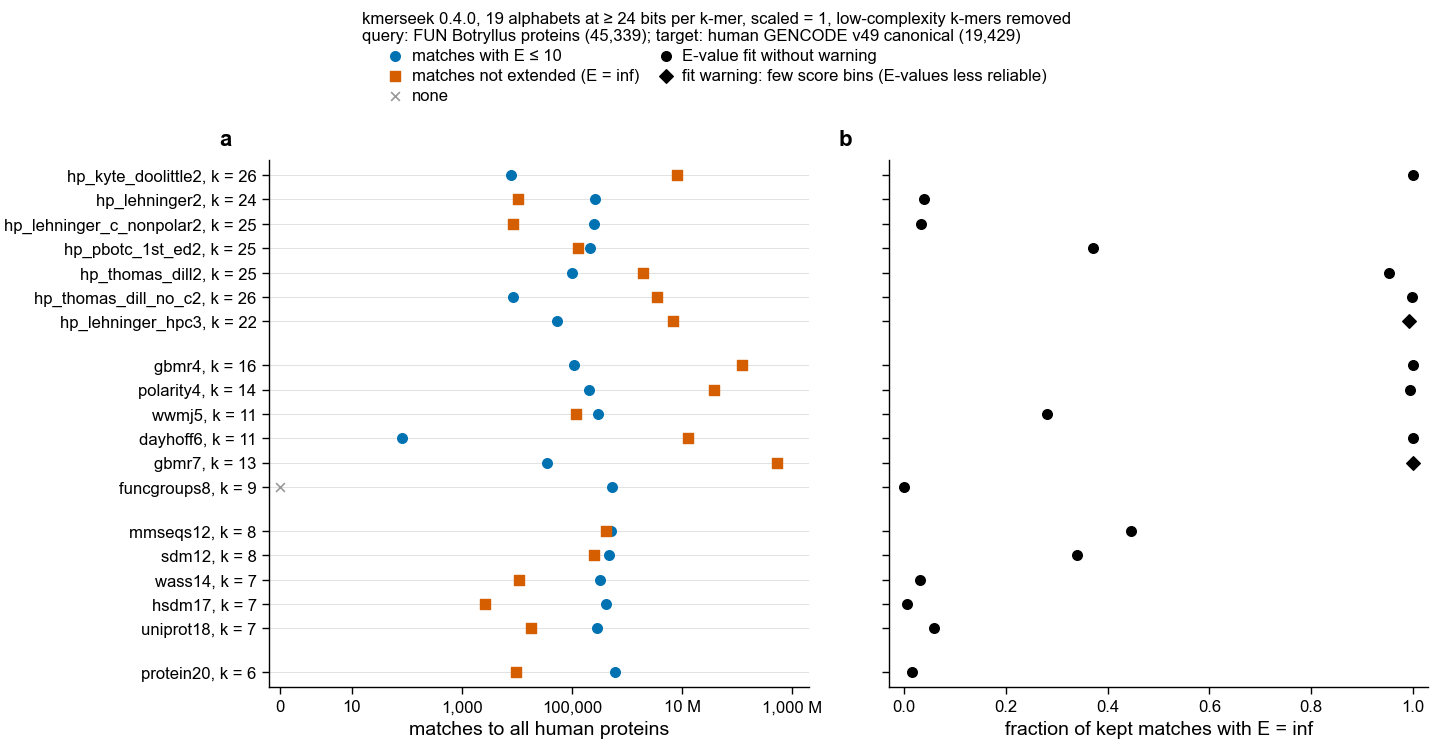

In [3]:
fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for a in ALPHABETS:
    r = runs.filter(pl.col("alphabet") == a).row(0, named=True)
    for n, colour, marker in [(r["n_evalue_le_10"], pf.OKABE_ITO["blue"], "o"),
                              (r["n_evalue_inf"], pf.OKABE_ITO["vermillion"], "s")]:
        if n > 0:
            ax_a.scatter(n, Y_OF[a], color=colour, marker=marker, s=12, zorder=3)
        else:
            ax_a.scatter(ZERO_X, Y_OF[a], color=pf.GREY, marker="x", s=10, linewidths=0.6, zorder=2)
    ax_b.scatter(r["fraction_inf"], Y_OF[a], color="black", s=12, zorder=3,
                 marker="o" if not r["fit_warning_few_bins"] else "D")
ax_a.scatter([], [], color=pf.OKABE_ITO["blue"], s=12, label="matches with E ≤ 10")
ax_a.scatter([], [], color=pf.OKABE_ITO["vermillion"], marker="s", s=12, label="matches not extended (E = inf)")
ax_a.scatter([], [], color=pf.GREY, marker="x", s=10, linewidths=0.6, label="none")
ax_b.scatter([], [], color="black", s=12, label="E-value fit without warning")
ax_b.scatter([], [], color="black", marker="D", s=12, label="fit warning: few score bins (E-values less reliable)")
ax_a.set_xscale("log")
ax_a.set_xlim(ZERO_X / 1.6, 2e9)
ax_a.set_xticks([ZERO_X, 10, 1e3, 1e5, 1e7, 1e9], ["0", "10", "1,000", "100,000", "10 M", "1,000 M"])
ax_a.set_xlabel("matches to all human proteins")
ax_b.set_xlim(-0.03, 1.03)
ax_b.set_xlabel("fraction of kept matches with E = inf")
alphabet_axis(ax_a)
pf.shared_legend(fig, ncol=2, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
for ax, letter in zip((ax_a, ax_b), "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "234a_runs_matches_extended_vs_not_kmerseek_botryllus_vs_gencode_19_alphabets")
plt.show()

How to read it: each row is one alphabet at its bit-matched k, grouped by number of classes.
Panel a counts kept matches to all human proteins; panel b is the share kmerseek did not
extend. An alphabet whose matches are mostly unextended gives few E-values to compare.

## 2. Botryllus proteins matching human immune genes and HLA, per alphabet

Counts at E ≤ 10 (the question as asked), E ≤ 1 and E ≤ 0.001 (the candidate cut-off).
Only matches with a finite E-value count here.

In [4]:
COLUMNS = ["query_name", "target_name", "region_evalue", "region_ka_bits", "region_tail_probability",
           "region_length", "region_n_shared_kmers", "region_start", "region_end", "target_start",
           "target_end", "region_subseq", "target_subseq"]
frames = []
for a in ALPHABETS:
    path = RUN_DIR / "immune" / f"{tag(a)}.immune.evalue_le_10.csv.gz"
    df = pl.read_csv(path, columns=COLUMNS, infer_schema_length=10_000,
                     schema_overrides={"region_evalue": pl.Float64, "region_tail_probability": pl.Float64})
    frames.append(with_gene_columns(df).with_columns(pl.lit(a).alias("alphabet")))
immune = pl.concat(frames).with_columns(pl.col("human_gene").str.starts_with("HLA-").alias("is_hla"))
immune = with_fun_name(immune)
assert immune["region_evalue"].is_finite().all() and (immune["region_evalue"] <= MAX_EVALUE).all()
assert immune["human_gene"].is_in(immune_genes).all()

rows = []
for a in ALPHABETS:
    sub = immune.filter(pl.col("alphabet") == a)
    for gene_set, s in [("all immune genes", sub), ("HLA genes", sub.filter("is_hla"))]:
        for cutoff in EVALUE_CUTOFFS:
            hit = s.filter(pl.col("region_evalue") <= cutoff)
            rows.append({"alphabet": a, "gene_set": gene_set, "max_evalue": cutoff, "n_matches": len(hit),
                         "n_botryllus_proteins": hit["query_name"].n_unique(),
                         "n_human_genes": hit["human_gene"].n_unique()})
counts = pl.DataFrame(rows)
counts.write_csv(OUT_DIR / "234_immune_hla_counts_by_evalue_kmerseek_botryllus_vs_gencode_19_alphabets.csv")
print(counts.pivot(on=["gene_set", "max_evalue"], index="alphabet", values="n_botryllus_proteins"))

shape: (19, 7)
┌──────────────────────────┬───────────────────────────┬──────────────────────────┬────────────────────────────┬────────────────────┬───────────────────┬─────────────────────┐
│ alphabet                 ┆ {"all immune genes",10.0} ┆ {"all immune genes",1.0} ┆ {"all immune genes",0.001} ┆ {"HLA genes",10.0} ┆ {"HLA genes",1.0} ┆ {"HLA genes",0.001} │
│ ---                      ┆ ---                       ┆ ---                      ┆ ---                        ┆ ---                ┆ ---               ┆ ---                 │
│ str                      ┆ i64                       ┆ i64                      ┆ i64                        ┆ i64                ┆ i64               ┆ i64                 │
╞══════════════════════════╪═══════════════════════════╪══════════════════════════╪════════════════════════════╪════════════════════╪═══════════════════╪═════════════════════╡
│ hp_kyte_doolittle2       ┆ 365                       ┆ 206                      ┆ 34                   

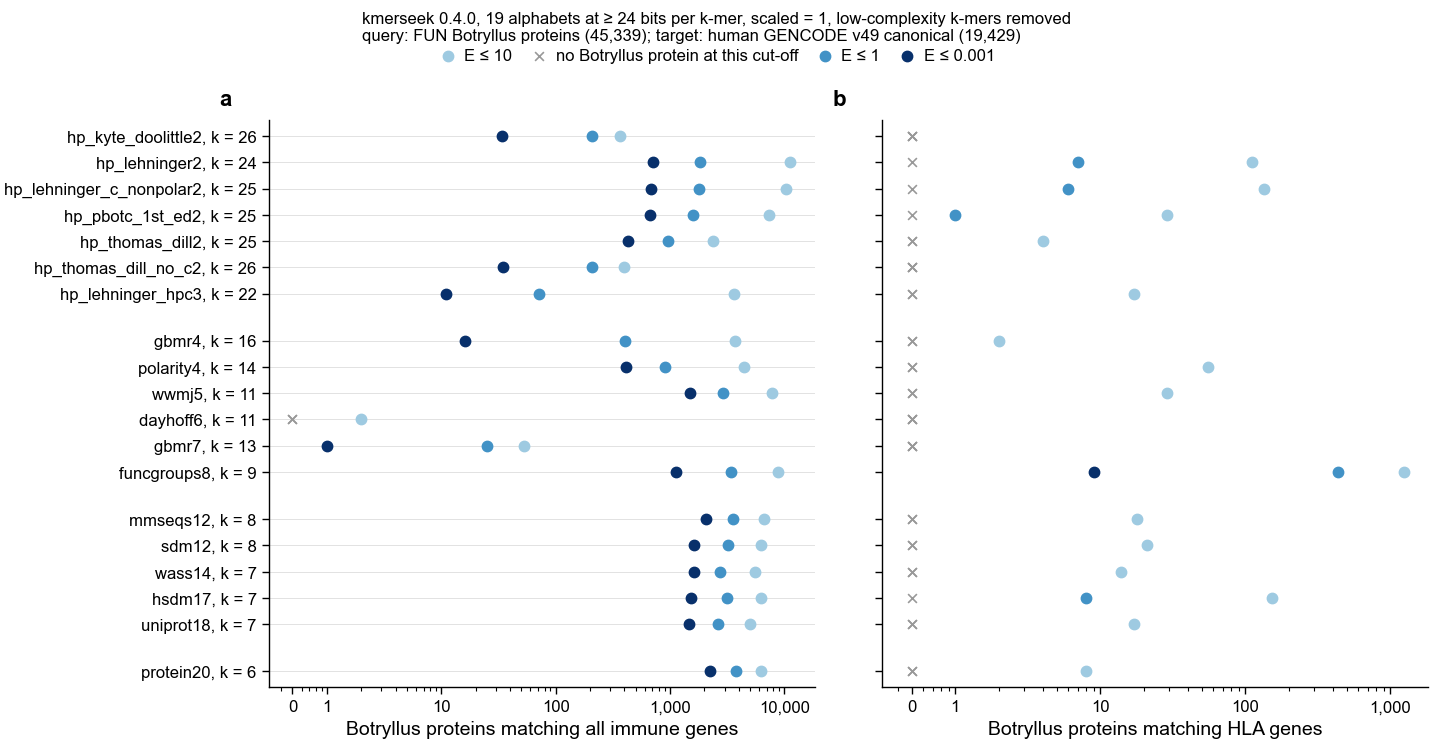

In [5]:
CUTOFF_STYLE = {10: ("#9ecae1", "E ≤ 10"), 1: ("#4292c6", "E ≤ 1"), STRICT_EVALUE: ("#08306b", "E ≤ 0.001")}

fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for ax, gene_set in zip(axs, ["all immune genes", "HLA genes"]):
    for cutoff, (colour, label) in CUTOFF_STYLE.items():
        sub = counts.filter((pl.col("gene_set") == gene_set) & (pl.col("max_evalue") == cutoff))
        ys = [Y_OF[a] for a in sub["alphabet"]]
        n = sub["n_botryllus_proteins"].to_numpy()
        ax.scatter(np.where(n > 0, n, np.nan), ys, color=colour, s=14, zorder=3, label=label)
        ax.scatter(np.where(n == 0, ZERO_X, np.nan), ys, color=pf.GREY, marker="x", s=10, linewidths=0.6,
                   zorder=2, label="no Botryllus protein at this cut-off")
    ax.set_xscale("log")
    ax.set_xlim(ZERO_X / 1.6, None)
    ticks = [t for t in [1, 10, 100, 1_000, 10_000, 100_000] if t <= max(1, counts.filter(pl.col("gene_set") == gene_set)["n_botryllus_proteins"].max()) * 3]
    ax.set_xticks([ZERO_X] + ticks, ["0"] + [f"{t:,}" for t in ticks])
    ax.set_xlabel(f"Botryllus proteins matching {gene_set}")
alphabet_axis(axs[0])
pf.shared_legend(fig, ncol=4, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "234b_botryllus_proteins_matching_immune_and_hla_by_evalue_kmerseek_19_alphabets")
plt.show()

How to read it: each row is one alphabet; light to dark blue is loose to strict E-value
cut-off. A grey × at 0 means no Botryllus protein passes that cut-off. Panel b is the question
of this notebook: a dark-blue dot in panel b would be an HLA match at the candidate cut-off.

## 3. The HLA matches in every alphabet, and which part of the HLA protein they cover

In [6]:
hla = immune.filter("is_hla")
hla_parts = HlaParts(dict(hla.group_by("human_gene").agg(pl.col("human_protein_length").first()).iter_rows()))
print(hla_parts.length_check)
hla = hla_parts.add_columns(hla)
assert set(hla["hla_part_matched"]) <= set(PART_COLOUR), set(hla["hla_part_matched"])
hla.sort("region_evalue").write_csv(OUT_DIR / "234_hla_matches_evalue_le_10_kmerseek_botryllus_vs_gencode_19_alphabets.csv")

best_hla = (hla.sort("region_evalue").group_by("alphabet", maintain_order=True)
            .agg(pl.len().alias("n_hla_matches"), pl.col("query_name").n_unique().alias("n_botryllus_proteins"),
                 pl.col("region_evalue").first().alias("best_evalue"),
                 pl.col("query_name").first().alias("best_botryllus_protein"),
                 pl.col("human_gene").first().alias("best_hla_gene"),
                 pl.col("hla_part_matched").first().alias("part_matched_by_best")))
best_hla = (arms.select("alphabet", "ksize").join(best_hla, on="alphabet", how="left")
            .with_columns(pl.col("n_hla_matches").fill_null(0), pl.col("n_botryllus_proteins").fill_null(0)))
print(best_hla)
print(f"\nHLA matches at E <= {STRICT_EVALUE} in any alphabet: {hla.filter(pl.col('region_evalue') <= STRICT_EVALUE).height}")
print("\nHLA part covered, all alphabets together:")
print(hla.group_by("hla_part_matched").agg(pl.len().alias("n_matches")).sort("n_matches", descending=True))

shape: (19, 5)
┌────────────┬─────────┬────────────────┬────────────────┬─────────────┐
│ human_gene ┆ uniprot ┆ uniprot_length ┆ gencode_length ┆ same_length │
│ ---        ┆ ---     ┆ ---            ┆ ---            ┆ ---         │
│ str        ┆ str     ┆ i64            ┆ i64            ┆ bool        │
╞════════════╪═════════╪════════════════╪════════════════╪═════════════╡
│ HLA-A      ┆ P04439  ┆ 365            ┆ 365            ┆ true        │
│ HLA-B      ┆ P01889  ┆ 362            ┆ 362            ┆ true        │
│ HLA-C      ┆ P10321  ┆ 366            ┆ 366            ┆ true        │
│ HLA-DMA    ┆ P28067  ┆ 261            ┆ 261            ┆ true        │
│ HLA-DMB    ┆ P28068  ┆ 263            ┆ 263            ┆ true        │
│ HLA-DOA    ┆ P06340  ┆ 250            ┆ 250            ┆ true        │
│ HLA-DOB    ┆ P13765  ┆ 273            ┆ 273            ┆ true        │
│ HLA-DPA1   ┆ P20036  ┆ 260            ┆ 260            ┆ true        │
│ HLA-DPB1   ┆ P04440  ┆ 258        

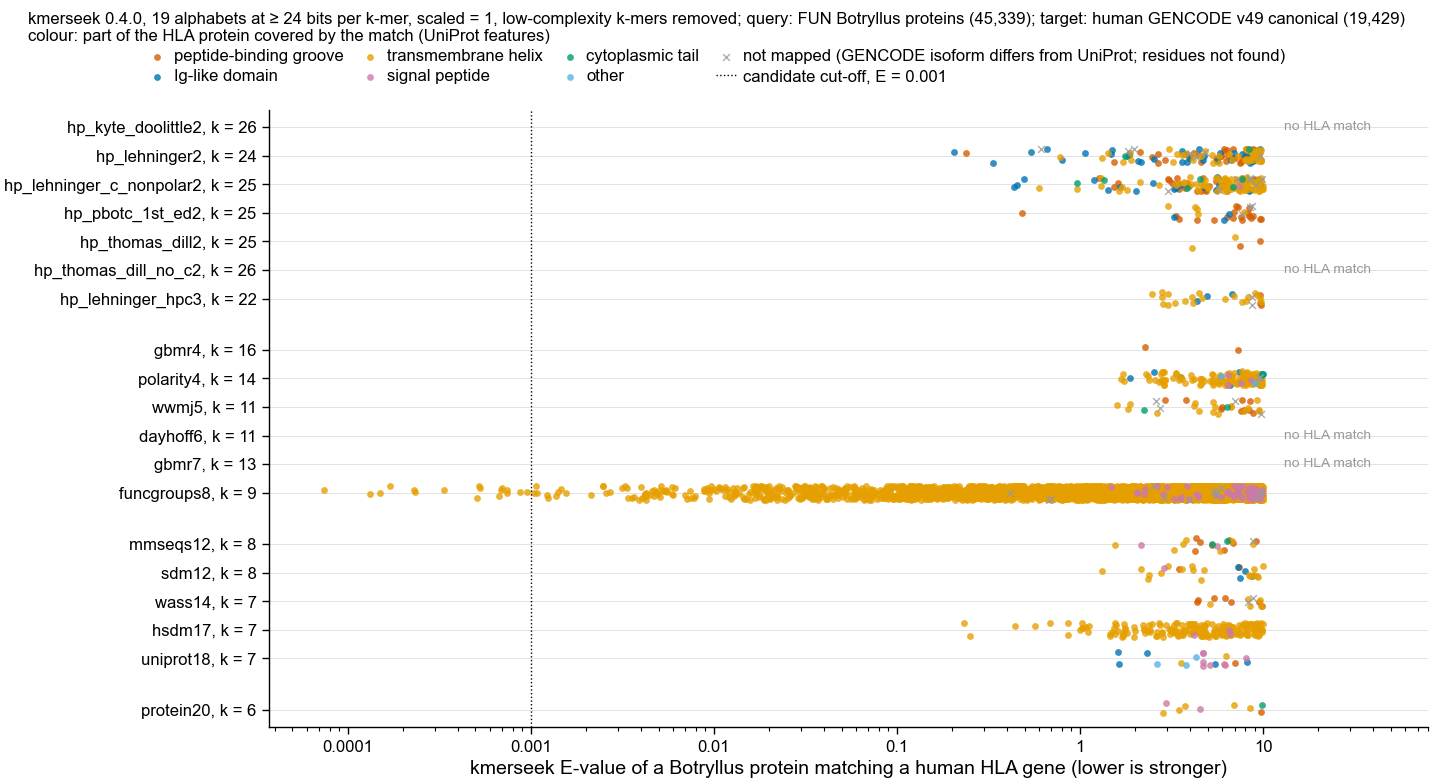

In [7]:
rng = np.random.default_rng(0)
fig, ax = pf.figure(pf.TWO_COLUMN_MM, 100)
for part, colour in PART_COLOUR.items():
    sub = hla.filter(pl.col("hla_part_matched") == part)
    if len(sub) == 0:
        continue
    ys = np.array([Y_OF[a] for a in sub["alphabet"]]) + rng.uniform(-0.25, 0.25, len(sub))
    ax.scatter(sub["region_evalue"], ys, color=colour, s=6, alpha=0.8, marker=PART_MARKER[part],
               linewidths=0 if PART_MARKER[part] == "o" else 0.5, label=part)
for a in ALPHABETS:
    if best_hla.filter(pl.col("alphabet") == a)["n_hla_matches"][0] == 0:
        ax.text(MAX_EVALUE * 1.3, Y_OF[a], "no HLA match", va="center", fontsize=5, color=pf.GREY)
ax.axvline(STRICT_EVALUE, color="black", linewidth=0.5, linestyle=":", label=f"candidate cut-off, E = {STRICT_EVALUE:g}")
ax.set_xscale("log")
left = min(STRICT_EVALUE, hla["region_evalue"].min()) / 2
ax.set_xlim(left, MAX_EVALUE * 8)
ticks = [t for t in [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1, 10] if t >= left]
ax.set_xticks(ticks, [f"{t:g}" if t >= 1e-3 else f"{t:.5f}".rstrip("0") for t in ticks])
ax.set_xlabel("kmerseek E-value of a Botryllus protein matching a human HLA gene (lower is stronger)")
alphabet_axis(ax)
pf.shared_legend(fig, ncol=4, title=f"{TOOL_LINE}; {QUERY_TARGET_LINE}\n"
                 "colour: part of the HLA protein covered by the match (UniProt features)")
pf.save(fig, FIG_DIR / "234c_hla_matches_evalue_and_part_kmerseek_botryllus_vs_gencode_19_alphabets")
plt.show()

How to read it: each dot is one Botryllus protein region matched to one HLA protein, in the
row of the alphabet that found it; further left is stronger. A dot left of the dotted line
would meet the candidate rule if its colour is vermillion (groove) or blue (Ig-like).

The best HLA match of each alphabet, in residues (Botryllus first, human second):

In [8]:
best_rows = hla.sort("region_evalue").group_by("alphabet", maintain_order=True).first()
for r in best_rows.sort("region_evalue").iter_rows(named=True):
    print(f"{r['alphabet']:<25} {r['query_name']:<24} vs {r['human_gene']:<9} E = {r['region_evalue']:.3g}  "
          f"human residues {r['target_start'] + 1}-{r['target_end']} ({r['hla_part_matched']})")
    print(f"  Botryllus {r['region_subseq'][:100]}")
    print(f"  human     {r['target_subseq'][:100]}\n")

funcgroups8               FUN018309_FUN018309      vs HLA-G     E = 7.46e-05  human residues 310-333 (transmembrane helix)
  Botryllus VIVLAVIVAVAIISIILLLIIVWK
  human     GIVAGLVVLAAVVTGAAVAAVLWR

hp_lehninger2             FUN028357_FUN028357-T2   vs HLA-A     E = 0.205  human residues 261-349 (Ig-like domain)
  Botryllus FEVQVTTTADYGIYNMCASTSKPRGRSCARLTIAHPTAAIEGIESNLTVLIGGSVAGAALILTVGVGLYLAFQRRNRKCQGTIANVIYN
  human     GDGTFQKWAAVVVPSGEEQRYTCHVQHEGLPKPLTLRWELSSQPTIPIVGIIAGLVLLGAVITGAVVAAVMWRRKSSDRKGGSYTQAAS

hsdm17                    FUN011297_FUN011297      vs HLA-G     E = 0.233  human residues 310-338 (transmembrane helix)
  Botryllus GIIAGIVLCAMFVVLAFTAFLIQWRKNRD
  human     GIVAGLVVLAAVVTGAAVAAVLWRKKSSD

hp_lehninger_c_nonpolar2  FUN016327_flrt2          vs HLA-B     E = 0.436  human residues 245-338 (Ig-like domain)
  Botryllus PTDYSDSRNGVARIDITNRTPGKLYIVCMMESSKDIADLTIEDCEFVETNSASPGQIHDNEAIVPVWLAILIALLVILVLAAIVLVVYCQRLNA
  human     GEDQTQDTELVETRPAGDRTFQKWAAVVVPSGEEQRYTCHVQH

**Every HLA groove or Ig-like match at E ≤ 1**, in residues (Botryllus first, human second).
"Same residue" counts positions where the two sequences carry the same amino acid; kmerseek
matches whole regions without gaps, so position i of one lines up with position i of the other.

In [9]:
GROOVE_OR_IG = ["peptide-binding groove", "Ig-like domain"]
groove_ig_le_1 = (hla.filter((pl.col("region_evalue") <= 1) & pl.col("hla_part_matched").is_in(GROOVE_OR_IG))
                  .sort("region_evalue", "alphabet", "query_name")
                  .with_columns(pl.struct("region_subseq", "target_subseq").map_elements(
                      lambda r: sum(a == b for a, b in zip(r["region_subseq"], r["target_subseq"])),
                      return_dtype=pl.Int64).alias("n_same_residue")))
groove_ig_le_1.write_csv(OUT_DIR / "234_hla_groove_or_ig_matches_evalue_le_1_kmerseek_botryllus_vs_gencode_19_alphabets.csv")
print(hla.filter(pl.col("region_evalue") <= 1).group_by("hla_part_matched")
      .agg(pl.len().alias("n_matches"), pl.col("query_name").n_unique().alias("n_botryllus_proteins"),
           pl.col("region_evalue").min().alias("best_evalue")).sort("n_matches", descending=True))
for r in groove_ig_le_1.iter_rows(named=True):
    print(f"\n{r['alphabet']:<25} {r['query_name']:<24} vs {r['human_gene']:<9} E = {r['region_evalue']:.2f}  "
          f"human residues {r['target_start'] + 1}-{r['target_end']} ({r['hla_part_matched']}); "
          f"same residue at {r['n_same_residue']} of {len(r['region_subseq'])} positions")
    print(f"  Botryllus {r['region_subseq'][:100]}")
    print(f"  human     {r['target_subseq'][:100]}")

shape: (5, 4)
┌───────────────────────────────────────────────────────────────┬───────────┬──────────────────────┬─────────────┐
│ hla_part_matched                                              ┆ n_matches ┆ n_botryllus_proteins ┆ best_evalue │
│ ---                                                           ┆ ---       ┆ ---                  ┆ ---         │
│ str                                                           ┆ u32       ┆ u32                  ┆ f64         │
╞═══════════════════════════════════════════════════════════════╪═══════════╪══════════════════════╪═════════════╡
│ transmembrane helix                                           ┆ 1232      ┆ 444                  ┆ 0.000075    │
│ Ig-like domain                                                ┆ 8         ┆ 5                    ┆ 0.205008    │
│ not mapped (GENCODE isoform differs from UniProt; residues n… ┆ 4         ┆ 4                    ┆ 0.417987    │
│ peptide-binding groove                                        ┆ 

**Matches found by several alphabets.** For each Botryllus protein and HLA gene, the number
of alphabets with a match at E ≤ 1, and the best E-value among them:

In [10]:
shared = (hla.filter(pl.col("region_evalue") <= 1)
          .group_by("query_name", "human_gene")
          .agg(pl.col("alphabet").n_unique().alias("n_alphabets"), pl.col("region_evalue").min().alias("best_evalue"),
               pl.col("alphabet").unique().sort().str.join(", ").alias("alphabets"),
               pl.col("hla_part_matched").mode().sort().first().alias("most_common_part"))
          .sort("n_alphabets", "best_evalue", "query_name", "human_gene", descending=[True, False, False, False]))
shared.write_csv(OUT_DIR / "234_hla_matches_shared_by_alphabets_evalue_le_1.csv")
print(shared.head(20))

shape: (20, 6)
┌────────────────────────┬────────────┬─────────────┬─────────────┬──────────────────────────────────────────────────────┬─────────────────────┐
│ query_name             ┆ human_gene ┆ n_alphabets ┆ best_evalue ┆ alphabets                                            ┆ most_common_part    │
│ ---                    ┆ ---        ┆ ---         ┆ ---         ┆ ---                                                  ┆ ---                 │
│ str                    ┆ str        ┆ u32         ┆ f64         ┆ str                                                  ┆ str                 │
╞════════════════════════╪════════════╪═════════════╪═════════════╪══════════════════════════════════════════════════════╪═════════════════════╡
│ FUN016327_flrt2        ┆ HLA-B      ┆ 3           ┆ 0.001042    ┆ funcgroups8, hp_lehninger2, hp_lehninger_c_nonpolar2 ┆ Ig-like domain      │
│ FUN028357_FUN028357-T1 ┆ HLA-A      ┆ 2           ┆ 0.072716    ┆ funcgroups8, hp_lehninger2                     

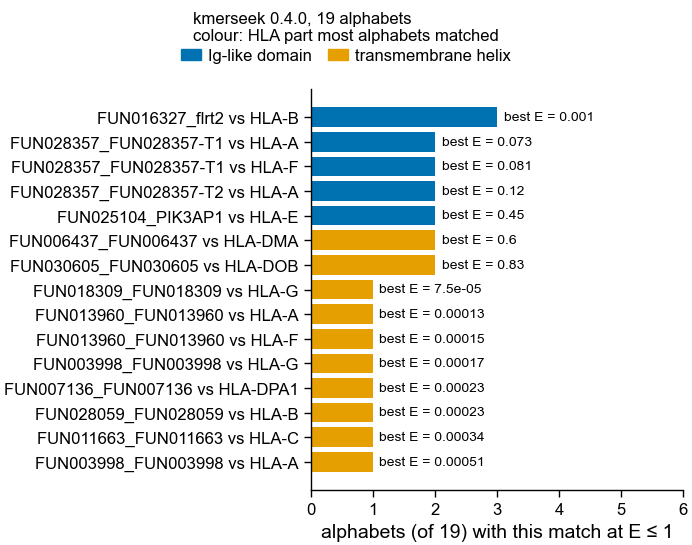

In [11]:
show = shared.head(15)
fig, ax = pf.figure(pf.ONE_COLUMN_MM, 70)
labels = [f"{q} vs {g}" for q, g in zip(show["query_name"], show["human_gene"])]
ax.barh(range(len(show)), show["n_alphabets"], color=[PART_COLOUR[p] for p in show["most_common_part"]])
for i, (n, e) in enumerate(zip(show["n_alphabets"], show["best_evalue"])):
    ax.text(n + 0.1, i, f"best E = {e:.2g}", va="center", fontsize=5)
ax.set_yticks(range(len(show)), labels)
ax.invert_yaxis()
ax.set_xlim(0, max(show["n_alphabets"].max() + 3, 4))
ax.set_xlabel(f"alphabets (of {len(ALPHABETS)}) with this match at E ≤ 1")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=PART_COLOUR[p], label=p) for p in dict.fromkeys(show["most_common_part"])],
           loc="outside upper center", ncol=2,
           title=f"kmerseek 0.4.0, {len(ALPHABETS)} alphabets\ncolour: HLA part most alphabets matched")
pf.save(fig, FIG_DIR / "234d_hla_matches_shared_by_alphabets_kmerseek_botryllus_vs_gencode")
plt.show()

## 4. The strongest matches to well-known immune families, per alphabet

Genes from the hand-picked family list of notebook 232 (HLA, antigen processing, Toll-like
and NOD-like receptors, complement, cytokines and receptors, interferons, TNF family,
NF-κB, IRF, TRAF, JAK/STAT, lymphocyte kinases, CD antigens, KIR/LILR, Fc receptors,
immunoglobulin and T-cell receptor genes, RAG, AIRE). Shown: every such gene with E ≤ 0.001
in at least one alphabet.

In [12]:
known = immune.filter(pl.col("human_gene").str.contains(KNOWN_IMMUNE_FAMILY_PATTERN))
best_known = known.group_by("human_gene", "alphabet").agg(pl.col("region_evalue").min().alias("best_evalue"))
strong_genes = (best_known.filter(pl.col("best_evalue") <= STRICT_EVALUE).group_by("human_gene")
                .agg(pl.col("best_evalue").min().alias("best_any"), pl.len().alias("n_alphabets_strict"))
                .sort("best_any"))
table = (best_known.filter(pl.col("human_gene").is_in(strong_genes["human_gene"].implode()))
         .pivot(on="alphabet", index="human_gene", values="best_evalue")
         .join(strong_genes, on="human_gene").sort("best_any"))
table = table.select("human_gene", "best_any", "n_alphabets_strict", *[a for a in ALPHABETS if a in table.columns])
table.write_csv(OUT_DIR / "234_best_evalue_known_immune_genes_by_alphabet.csv")
print(f"{strong_genes.height} well-known immune genes with E <= {STRICT_EVALUE} in at least one alphabet")
print(table.select("human_gene", "best_any", "n_alphabets_strict"))

59 well-known immune genes with E <= 0.001 in at least one alphabet
shape: (59, 3)
┌─────────────────┬────────────┬────────────────────┐
│ human_gene      ┆ best_any   ┆ n_alphabets_strict │
│ ---             ┆ ---        ┆ ---                │
│ str             ┆ f64        ┆ u32                │
╞═════════════════╪════════════╪════════════════════╡
│ PSMB8           ┆ 5.4582e-46 ┆ 12                 │
│ TRAF3           ┆ 1.0706e-42 ┆ 13                 │
│ PSMB10          ┆ 2.7868e-32 ┆ 11                 │
│ LCK             ┆ 1.6436e-25 ┆ 12                 │
│ BTK             ┆ 1.0119e-24 ┆ 9                  │
│ NFKB1           ┆ 4.0975e-24 ┆ 10                 │
│ SYK             ┆ 7.9489e-23 ┆ 11                 │
│ IRF4            ┆ 5.2744e-21 ┆ 8                  │
│ TRAF2           ┆ 3.4856e-18 ┆ 8                  │
│ PSMB9           ┆ 4.4784e-17 ┆ 8                  │
│ ZAP70           ┆ 1.8195e-13 ┆ 12                 │
│ TAP2            ┆ 3.0277e-13 ┆ 10                 │

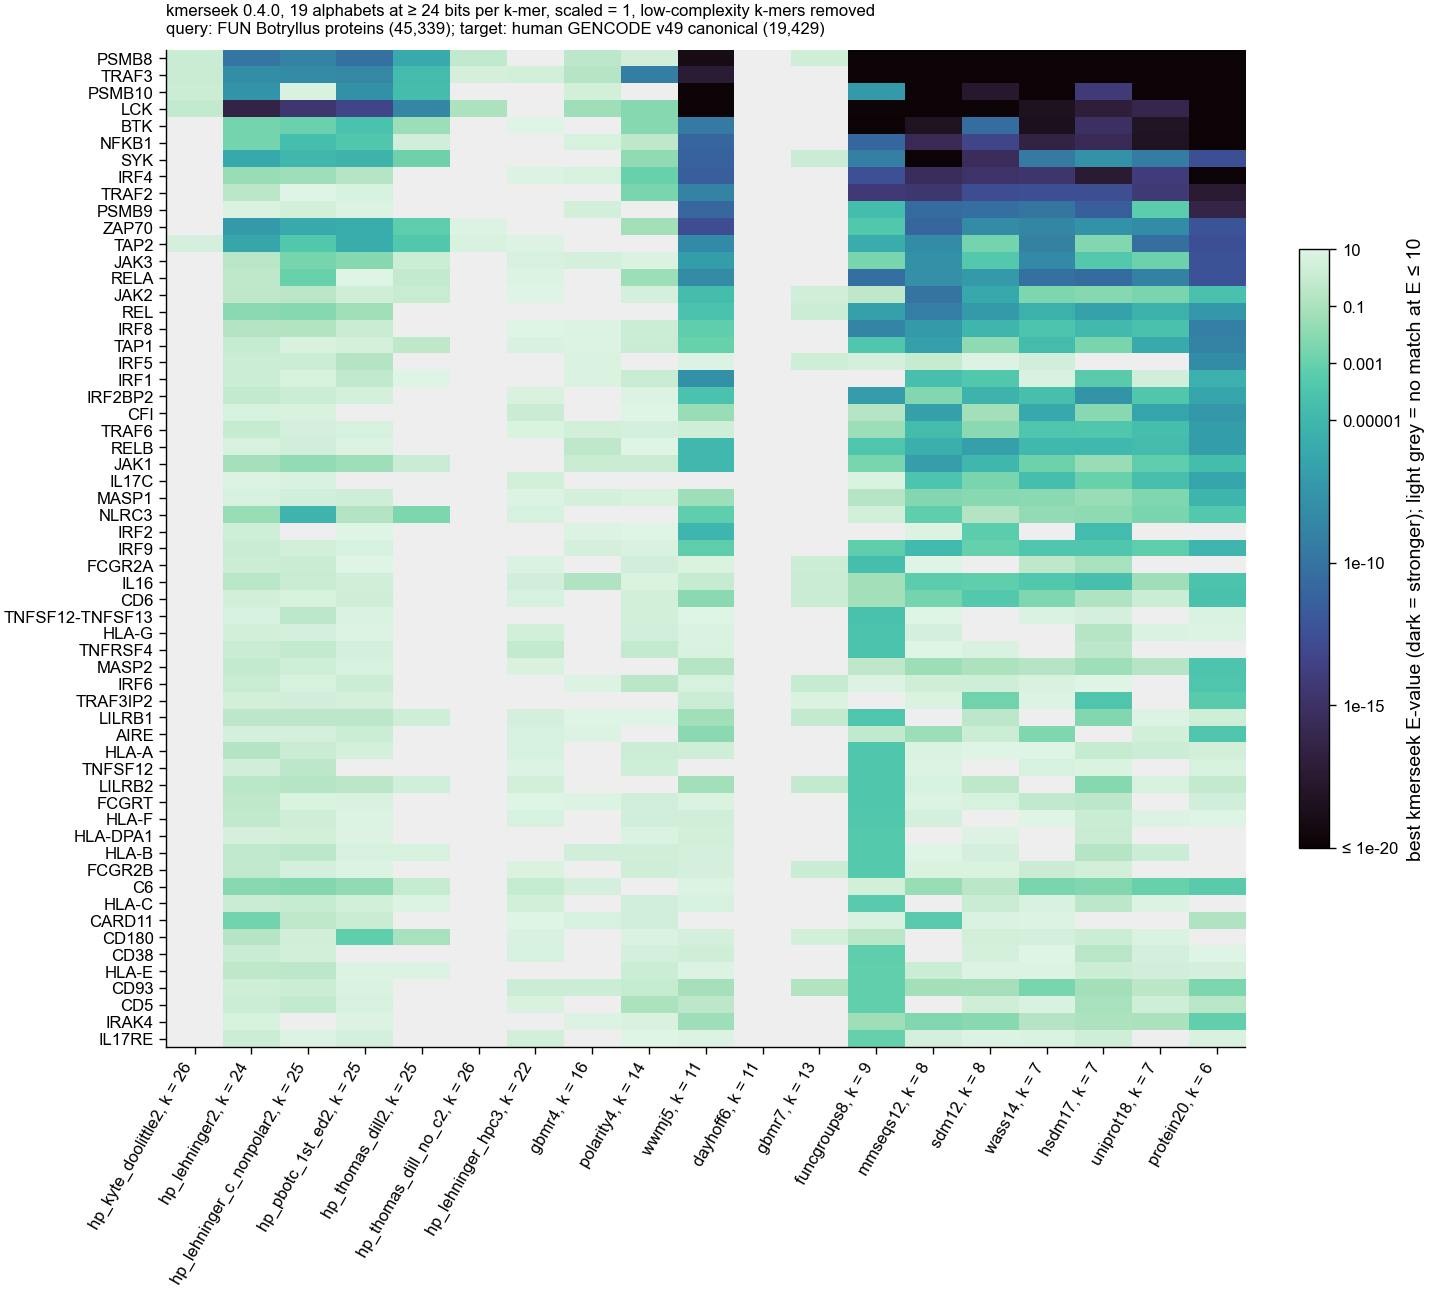

In [13]:
genes = table["human_gene"].to_list()
grid = np.full((len(genes), len(ALPHABETS)), np.nan)
for i, g in enumerate(genes):
    row = table.filter(pl.col("human_gene") == g).row(0, named=True)
    for j, a in enumerate(ALPHABETS):
        if a in row and row[a] is not None:
            grid[i, j] = np.log10(max(row[a], 1e-50))
cmap = plt.get_cmap("mako").copy()
cmap.set_bad("#eeeeee")
fig, ax = pf.figure(pf.TWO_COLUMN_MM, min(165, max(40, 30 + 2.6 * len(genes))))
FLOOR = -20  # stronger than 1e-20 all get the darkest colour, so the weaker cells stay readable
im = ax.imshow(np.ma.masked_invalid(np.clip(grid, FLOOR, None)), aspect="auto", cmap=cmap, vmin=FLOOR, vmax=1)
ax.set_xticks(range(len(ALPHABETS)), [LABEL_OF[a] for a in ALPHABETS], rotation=60, ha="right")
ax.set_yticks(range(len(genes)), genes)
cbar = fig.colorbar(im, ax=ax, shrink=0.6)
cbar.set_ticks([-20, -15, -10, -5, -3, -1, 1],
               labels=["≤ 1e-20", "1e-15", "1e-10", "0.00001", "0.001", "0.1", "10"])
cbar.set_label("best kmerseek E-value (dark = stronger); light grey = no match at E ≤ 10")
ax.set_title(f"{TOOL_LINE}\n{QUERY_TARGET_LINE}", fontsize=6, loc="left")
pf.save(fig, FIG_DIR / "234e_best_evalue_known_immune_genes_by_alphabet_kmerseek_botryllus")
plt.show()

## 5. Immune matches kmerseek did not extend (E = inf)

Summarised on Sherlock per alphabet: matches, Botryllus proteins and human immune genes, and
every unextended match to an HLA gene. With no E-value, the only measure of strength is
`region_tail_probability`, the chance of this many shared k-mers in the region. kmerseek
0.4.0 writes it uncorrected, and each alphabet makes 45,339 × 19,429 ≈ 0.88 billion
protein-pair comparisons, so a match counts here only below 0.05 / 0.88 billion ≈ 5.7e-11
(Bonferroni). The residues of the strongest ones are printed so they can be judged by eye.

In [14]:
inf_rows, inf_hla = [], []
for a in ALPHABETS:
    stem = RUN_DIR / "immune" / f"{tag(a)}.immune.evalue_inf"
    t = pl.read_csv(f"{stem}.totals.tsv", separator="\t").row(0, named=True)
    h = pl.read_csv(f"{stem}.hla.csv.gz", infer_schema_length=10_000,
                    schema_overrides={"region_evalue": pl.Float64, "region_tail_probability": pl.Float64})
    inf_rows.append({"alphabet": a, **t, "n_hla_matches": len(h),
                     "n_hla_botryllus_proteins": h["query_name"].n_unique() if len(h) else 0})
    if len(h):
        inf_hla.append(with_gene_columns(h.select(COLUMNS)).with_columns(pl.lit(a).alias("alphabet")))
inf_totals = pl.DataFrame(inf_rows)
inf_totals.write_csv(OUT_DIR / "234_immune_matches_not_extended_totals_19_alphabets.csv")
print(inf_totals)
inf_hla = pl.concat(inf_hla) if inf_hla else None
if inf_hla is not None:
    inf_hla = hla_parts.add_columns(inf_hla) if set(inf_hla["human_gene"]) <= set(hla_parts.same_length) else inf_hla
    threshold = 0.05 / N_PAIRS
    # only the matches that pass the corrected threshold are committed; all of them are in RUN_DIR
    (inf_hla.filter(pl.col("region_tail_probability") < threshold).sort("region_tail_probability")
     .write_csv(OUT_DIR / "234_hla_matches_not_extended_below_corrected_p_19_alphabets.csv"))
    inf_hla_counts = (inf_hla.group_by("alphabet")
                      .agg(pl.len().alias("n_hla_matches"),
                           pl.col("query_name").n_unique().alias("n_botryllus_proteins"),
                           (pl.col("region_tail_probability") < threshold).sum().alias("n_below_corrected_0.05"),
                           (pl.col("region_tail_probability") == 0).sum().alias("n_p_exactly_0"))
                      .sort("n_hla_matches", descending=True))
    print(f"\nUnextended HLA matches per alphabet; corrected threshold 0.05 / {N_PAIRS:,} pairs = {threshold:.2g}")
    print(inf_hla_counts)
    print("\nThe 6 with the most shared k-mers among those below the threshold, in residues:")
    top = (inf_hla.filter(pl.col("region_tail_probability") < threshold)
           .sort("region_n_shared_kmers", "region_tail_probability", descending=[True, False]).head(6))
    for r in top.iter_rows(named=True):
        print(f"{r['alphabet']:<20} {r['query_name']:<18} vs {r['human_gene']:<9} p = {r['region_tail_probability']:.2g}, "
              f"{r['region_n_shared_kmers']} shared k-mers ({r['hla_part_matched']})")
        print(f"  Botryllus {r['region_subseq'][:80]}")
        print(f"  human     {r['target_subseq'][:80]}")

shape: (19, 6)
┌──────────────────────────┬───────────┬──────────────────────┬───────────────┬───────────────┬──────────────────────────┐
│ alphabet                 ┆ n_matches ┆ n_botryllus_proteins ┆ n_human_genes ┆ n_hla_matches ┆ n_hla_botryllus_proteins │
│ ---                      ┆ ---       ┆ ---                  ┆ ---           ┆ ---           ┆ ---                      │
│ str                      ┆ i64       ┆ i64                  ┆ i64           ┆ i64           ┆ i64                      │
╞══════════════════════════╪═══════════╪══════════════════════╪═══════════════╪═══════════════╪══════════════════════════╡
│ hp_kyte_doolittle2       ┆ 295973    ┆ 5720                 ┆ 514           ┆ 71            ┆ 29                       │
│ hp_lehninger2            ┆ 33        ┆ 13                   ┆ 7             ┆ 0             ┆ 0                        │
│ hp_lehninger_c_nonpolar2 ┆ 36        ┆ 22                   ┆ 12            ┆ 0             ┆ 0                        │
│


Unextended HLA matches per alphabet; corrected threshold 0.05 / 880,891,431 pairs = 5.7e-11
shape: (6, 5)
┌────────────────────┬───────────────┬──────────────────────┬────────────────────────┬───────────────┐
│ alphabet           ┆ n_hla_matches ┆ n_botryllus_proteins ┆ n_below_corrected_0.05 ┆ n_p_exactly_0 │
│ ---                ┆ ---           ┆ ---                  ┆ ---                    ┆ ---           │
│ str                ┆ u32           ┆ u32                  ┆ u32                    ┆ u32           │
╞════════════════════╪═══════════════╪══════════════════════╪════════════════════════╪═══════════════╡
│ gbmr7              ┆ 90055         ┆ 20280                ┆ 371                    ┆ 13            │
│ polarity4          ┆ 65480         ┆ 5253                 ┆ 94                     ┆ 5             │
│ gbmr4              ┆ 36262         ┆ 11462                ┆ 540                    ┆ 41            │
│ hp_lehninger_hpc3  ┆ 5958          ┆ 2666                 ┆ 746    

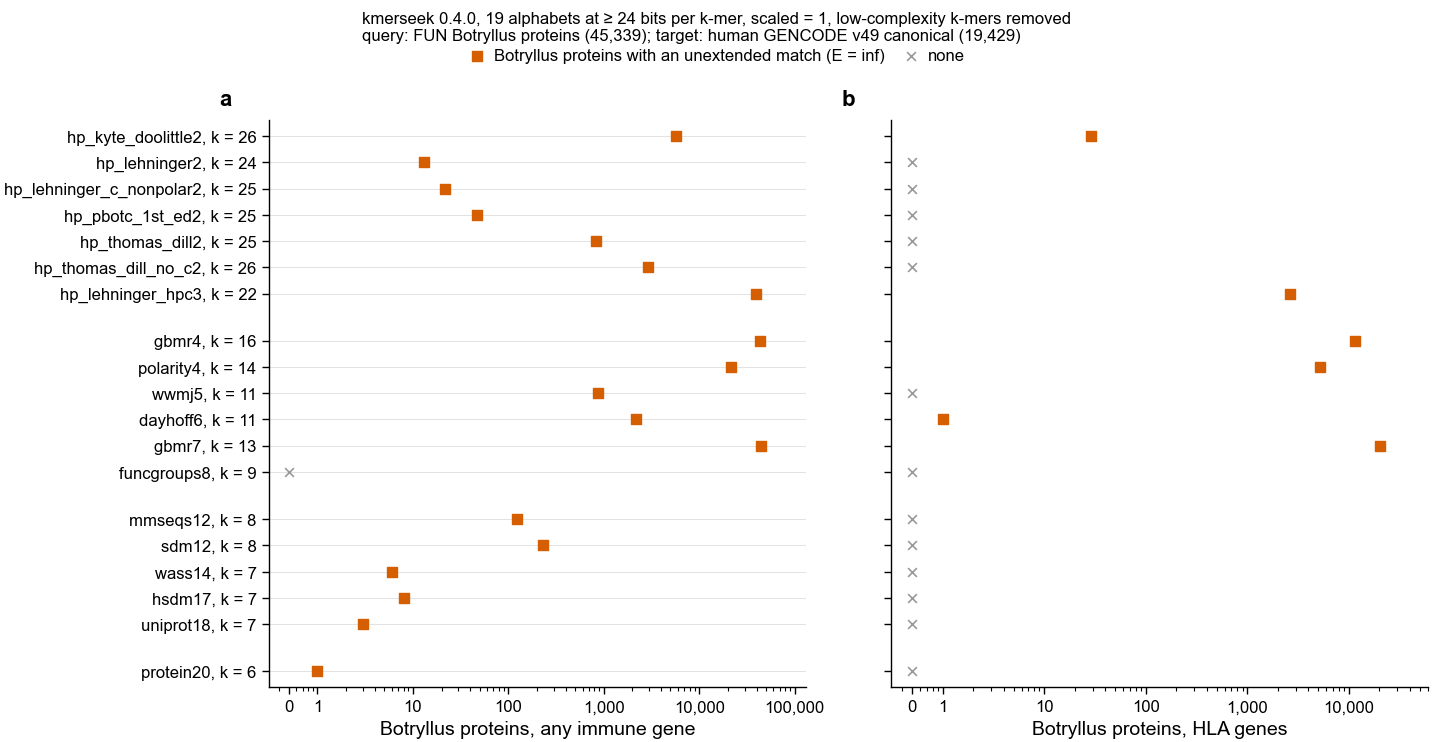

In [15]:
fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for ax, col in [(ax_a, "n_botryllus_proteins"), (ax_b, "n_hla_botryllus_proteins")]:
    n = inf_totals[col].to_numpy()
    ys = [Y_OF[a] for a in inf_totals["alphabet"]]
    ax.scatter(np.where(n > 0, n, np.nan), ys, color=pf.OKABE_ITO["vermillion"], marker="s", s=12, zorder=3,
               label="Botryllus proteins with an unextended match (E = inf)")
    ax.scatter(np.where(n == 0, ZERO_X, np.nan), ys, color=pf.GREY, marker="x", s=10, linewidths=0.6,
               label="none")
    ax.set_xscale("log")
    ax.set_xlim(ZERO_X / 1.6, max(n.max(), 1) * 3)
    ticks = [t for t in [1, 10, 100, 1_000, 10_000, 100_000] if t <= max(n.max(), 1) * 3]
    ax.set_xticks([ZERO_X] + ticks, ["0"] + [f"{t:,}" for t in ticks])
ax_a.set_xlabel("Botryllus proteins, any immune gene")
ax_b.set_xlabel("Botryllus proteins, HLA genes")
alphabet_axis(ax_a)
pf.shared_legend(fig, ncol=2, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
for ax, letter in zip((ax_a, ax_b), "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "234f_immune_matches_not_extended_kmerseek_botryllus_vs_gencode_19_alphabets")
plt.show()

## 6. Does kmerseek's best human match agree with the gene name funannotate gave?

17,455 FUN proteins carry a gene name from funannotate (`FUN000002_NLRC5`), assigned by its
own similarity search. For each named Botryllus protein with an immune match at E ≤ 0.001,
take its best match in each alphabet and ask whether the human gene has the same name. This
checks the run: alphabets that find real homologues should agree with funannotate often.
Names differ for paralogues (a Botryllus protein named after one family member can match
another best), so agreement well below 100% is expected. Only matches to human immune genes
were kept on Sherlock, so "best match" here means the best immune-gene match: a protein whose
same-named human gene is not on the immune list cannot agree.

In [16]:
best_per_protein = (immune.filter(pl.col("fun_name").is_not_null() & (pl.col("region_evalue") <= STRICT_EVALUE))
                    .sort("region_evalue").group_by("alphabet", "query_name", maintain_order=True).first()
                    .with_columns((pl.col("fun_name").str.to_uppercase() == pl.col("human_gene")).alias("same_name")))
agree = (best_per_protein.group_by("alphabet")
         .agg(pl.len().alias("n_named_botryllus_proteins"), pl.col("same_name").sum().alias("n_same_name"))
         .with_columns((pl.col("n_same_name") / pl.col("n_named_botryllus_proteins")).alias("fraction_same_name")))
agree = arms.select("alphabet", "ksize").join(agree, on="alphabet", how="left").fill_null(0)
agree.write_csv(OUT_DIR / "234_fun_name_agrees_with_best_human_immune_match_evalue_le_0.001.csv")
print(agree)
print("\nExamples where the names differ, protein20:")
print(best_per_protein.filter((pl.col("alphabet") == "protein20") & ~pl.col("same_name"))
      .select("query_name", "human_gene", "region_evalue").head(10))

shape: (19, 5)
┌──────────────────────────┬───────┬────────────────────────────┬─────────────┬────────────────────┐
│ alphabet                 ┆ ksize ┆ n_named_botryllus_proteins ┆ n_same_name ┆ fraction_same_name │
│ ---                      ┆ ---   ┆ ---                        ┆ ---         ┆ ---                │
│ str                      ┆ i64   ┆ u32                        ┆ u32         ┆ f64                │
╞══════════════════════════╪═══════╪════════════════════════════╪═════════════╪════════════════════╡
│ hp_kyte_doolittle2       ┆ 26    ┆ 34                         ┆ 22          ┆ 0.647059           │
│ hp_lehninger2            ┆ 24    ┆ 663                        ┆ 272         ┆ 0.410256           │
│ hp_lehninger_c_nonpolar2 ┆ 25    ┆ 635                        ┆ 262         ┆ 0.412598           │
│ hp_pbotc_1st_ed2         ┆ 25    ┆ 618                        ┆ 271         ┆ 0.438511           │
│ hp_thomas_dill2          ┆ 25    ┆ 403                        ┆ 205       

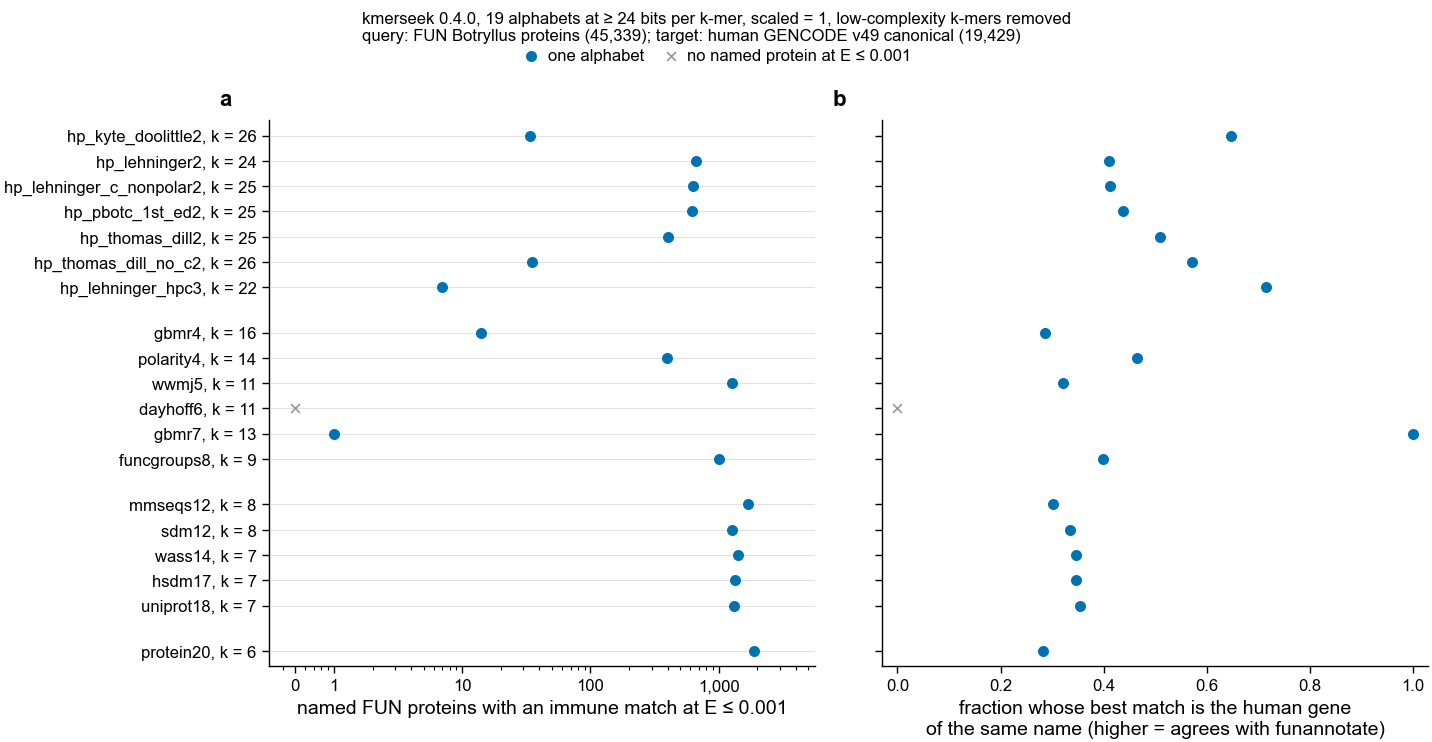

In [17]:
fig, (ax_a, ax_b) = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for a in ALPHABETS:
    r = agree.filter(pl.col("alphabet") == a).row(0, named=True)
    n = r["n_named_botryllus_proteins"]
    if n > 0:
        ax_a.scatter(n, Y_OF[a], color=pf.OKABE_ITO["blue"], s=12, zorder=3)
        ax_b.scatter(r["fraction_same_name"], Y_OF[a], color=pf.OKABE_ITO["blue"], s=12, zorder=3)
    else:
        ax_a.scatter(ZERO_X, Y_OF[a], color=pf.GREY, marker="x", s=10, linewidths=0.6, zorder=2)
        ax_b.scatter(0, Y_OF[a], color=pf.GREY, marker="x", s=10, linewidths=0.6, zorder=2)
ax_a.scatter([], [], color=pf.OKABE_ITO["blue"], s=12, label="one alphabet")
ax_a.scatter([], [], color=pf.GREY, marker="x", s=10, linewidths=0.6, label="no named protein at E ≤ 0.001")
ax_a.set_xscale("log")
top = max(agree["n_named_botryllus_proteins"].max(), 1) * 3
ticks = [t for t in [1, 10, 100, 1_000, 10_000] if t <= top]
ax_a.set_xlim(ZERO_X / 1.6, top)
ax_a.set_xticks([ZERO_X] + ticks, ["0"] + [f"{t:,}" for t in ticks])
ax_a.set_xlabel("named FUN proteins with an immune match at E ≤ 0.001")
ax_b.set_xlim(-0.03, 1.03)
ax_b.set_xlabel("fraction whose best match is the human gene\nof the same name (higher = agrees with funannotate)")
alphabet_axis(ax_a)
pf.shared_legend(fig, ncol=2, title=f"{TOOL_LINE}\n{QUERY_TARGET_LINE}")
for ax, letter in zip((ax_a, ax_b), "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "234g_fun_name_agrees_with_best_human_immune_match_kmerseek_alphabets")
plt.show()

## 7. Old proteome (notebook 233) against new proteome, per alphabet

Botryllus proteins matching any immune gene and HLA genes at each E-value cut-off, read from
notebook 233's committed counts. The old proteome has 72,617 translations and the new one
45,339, so with the same E-value cut-off the old one gets about 1.6 times as many chance
matches.

In [18]:
old_counts = pl.read_csv("233_outputs/233_immune_hla_counts_by_evalue_kmerseek_botryllus_vs_gencode_19_alphabets.csv")
both = (old_counts.rename({"n_botryllus_proteins": "old_Bs_proteins", "n_matches": "old_matches"})
        .select("alphabet", "gene_set", "max_evalue", "old_Bs_proteins", "old_matches")
        .join(counts.rename({"n_botryllus_proteins": "new_FUN_proteins", "n_matches": "new_matches"})
              .select("alphabet", "gene_set", "max_evalue", "new_FUN_proteins", "new_matches"),
              on=["alphabet", "gene_set", "max_evalue"], how="inner"))
both.write_csv(OUT_DIR / "234_immune_hla_counts_old_vs_fun_proteome_by_evalue.csv")
print(both.filter(pl.col("max_evalue") == STRICT_EVALUE).sort("gene_set", "alphabet"))

shape: (38, 7)
┌──────────────────────────┬──────────────────┬────────────┬─────────────────┬─────────────┬──────────────────┬─────────────┐
│ alphabet                 ┆ gene_set         ┆ max_evalue ┆ old_Bs_proteins ┆ old_matches ┆ new_FUN_proteins ┆ new_matches │
│ ---                      ┆ ---              ┆ ---        ┆ ---             ┆ ---         ┆ ---              ┆ ---         │
│ str                      ┆ str              ┆ f64        ┆ i64             ┆ i64         ┆ i64              ┆ i64         │
╞══════════════════════════╪══════════════════╪════════════╪═════════════════╪═════════════╪══════════════════╪═════════════╡
│ dayhoff6                 ┆ HLA genes        ┆ 0.001      ┆ 0               ┆ 0           ┆ 0                ┆ 0           │
│ funcgroups8              ┆ HLA genes        ┆ 0.001      ┆ 9               ┆ 14          ┆ 9                ┆ 17          │
│ gbmr4                    ┆ HLA genes        ┆ 0.001      ┆ 0               ┆ 0           ┆ 0         

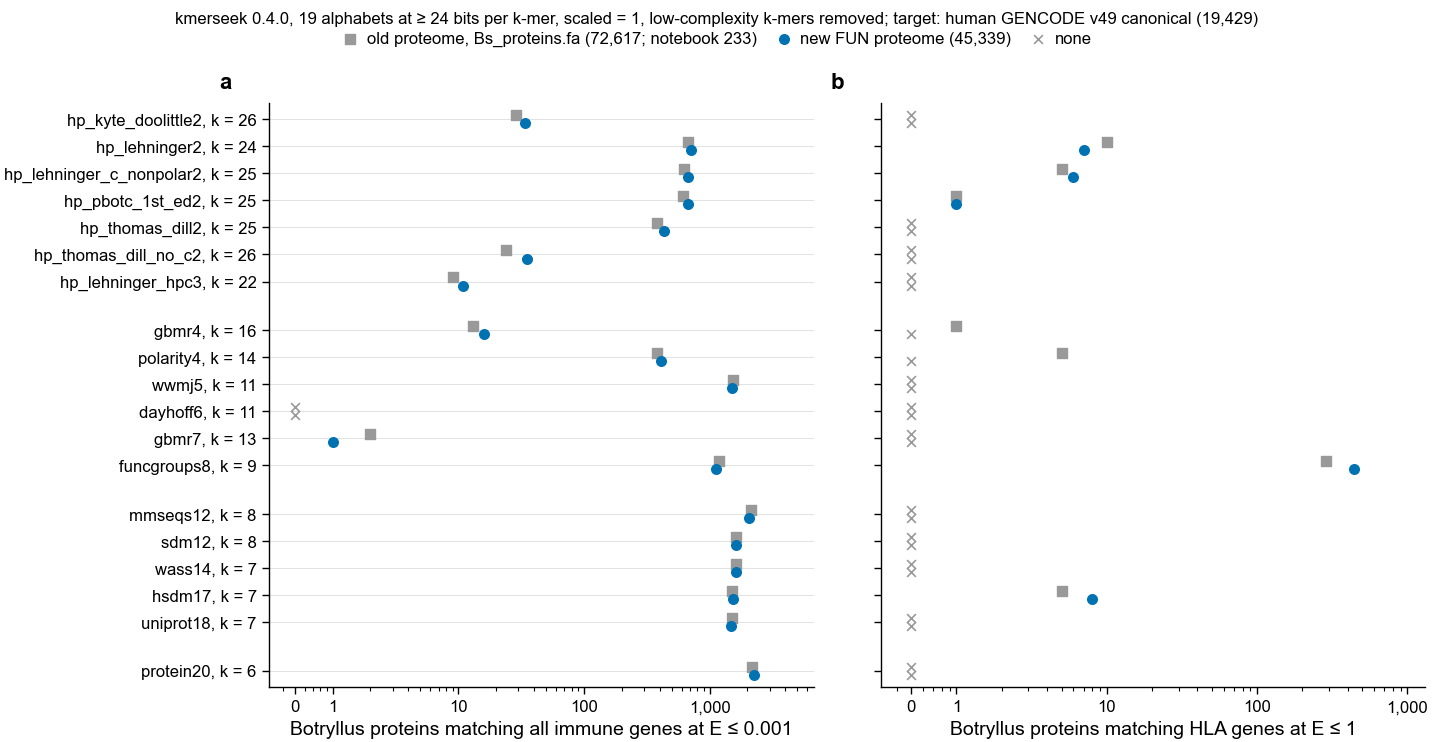

In [19]:
fig, axs = pf.figure(pf.TWO_COLUMN_MM, 95, ncols=2, sharey=True)
for ax, gene_set, cutoff in [(axs[0], "all immune genes", STRICT_EVALUE), (axs[1], "HLA genes", 1)]:
    sub = both.filter((pl.col("gene_set") == gene_set) & (pl.col("max_evalue") == cutoff))
    for name, colour, marker, dy in [("old_Bs_proteins", pf.GREY, "s", -0.15), ("new_FUN_proteins", pf.OKABE_ITO["blue"], "o", 0.15)]:
        n = sub[name].to_numpy()
        ys = np.array([Y_OF[a] for a in sub["alphabet"]]) + dy
        ax.scatter(np.where(n > 0, n, np.nan), ys, color=colour, marker=marker, s=12, zorder=3)
        ax.scatter(np.where(n == 0, ZERO_X, np.nan), ys, color=pf.GREY, marker="x", s=10, linewidths=0.6, zorder=2)
    ax.set_xscale("log")
    top = max(sub["old_Bs_proteins"].max(), sub["new_FUN_proteins"].max(), 1) * 3
    ticks = [t for t in [1, 10, 100, 1_000, 10_000] if t <= top]
    ax.set_xlim(ZERO_X / 1.6, top)
    ax.set_xticks([ZERO_X] + ticks, ["0"] + [f"{t:,}" for t in ticks])
    ax.set_xlabel(f"Botryllus proteins matching {gene_set} at E ≤ {cutoff:g}")
axs[0].scatter([], [], color=pf.GREY, marker="s", s=12, label="old proteome, Bs_proteins.fa (72,617; notebook 233)")
axs[0].scatter([], [], color=pf.OKABE_ITO["blue"], s=12, label="new FUN proteome (45,339)")
axs[0].scatter([], [], color=pf.GREY, marker="x", s=10, linewidths=0.6, label="none")
alphabet_axis(axs[0])
pf.shared_legend(fig, ncol=3, title=f"{TOOL_LINE}; target: human GENCODE v49 canonical (19,429)")
for ax, letter in zip(axs, "ab"):
    pf.panel_label(ax, letter)
pf.save(fig, FIG_DIR / "234h_immune_hla_matches_old_vs_fun_proteome_kmerseek_alphabets")
plt.show()

How to read it: each row is one alphabet; grey squares are the old proteome, blue dots the new
one. Panel a counts Botryllus proteins with an immune match at E ≤ 0.001; panel b counts those
with an HLA match at E ≤ 1, the loosest cut-off notebook 233 inspected by hand.

## Summary and conclusions

Tool for every number below: kmerseek 0.4.0, the 19 alphabets of notebook 233, each at the k
that carries at least 24 bits per k-mer (protein20 at k = 6), scaled = 1, low-complexity
k-mers removed. Query: 45,339 FUN Botryllus proteins. Target: 19,429 human GENCODE v49
canonical proteins.

1. **No FUN protein is an MHC-like candidate under the rule written at the top.** Across the
   19 alphabets there are 4,981 HLA matches with E ≤ 10, from 1,584 FUN proteins. The 17
   matches with E ≤ 0.001 come from 9 proteins, all from funcgroups8 (k = 9), and all cover
   the HLA transmembrane helix. The strongest is FUN018309 (`VIVLAVIVAVAIISIILLLIIVWK`)
   against the HLA-G helix (`GIVAGLVVLAAVVTGAAVAAVLWR`), E = 0.000075.

   At E ≤ 1 there are 1,247 HLA matches from 450 FUN proteins, and 1,224 of them come from
   funcgroups8. Only 10 cover the groove or the Ig-like domain. They come from 7 FUN records
   (6 genes, since FUN028357 has two copies, -T1 and -T2), all from HP alphabets, with E
   between 0.21 and 0.79. They have the same residue at 0 to 12 positions out of 55 to 94,
   about what two unrelated sequences share. Most of the Ig-like matches run on into the HLA
   membrane helix (human residues 245 to 349). The FUN names of these proteins are not
   MHC-like: flrt2 (a leucine-rich repeat membrane protein), PIK3AP1, PRR11, FADF, and three
   with no gene name.

2. **The new gene models change little.** At E ≤ 0.001, summed over the 19 alphabets (a
   protein found by several alphabets counts once for each), 16,212 FUN proteins have an
   immune match against 16,040 old proteins (notebook 233), although the FUN proteome has
   38% fewer proteins. HLA matches at E ≤ 0.001 are
   funcgroups8 helix matches in both: 9 proteins each, 17 matches against 14. At E ≤ 1,
   polarity4 and gbmr4 lose their few HLA matches. funcgroups8 rises from 285 to 438 FUN
   proteins, all of them helix matches.

3. **Well-known immune genes are found strongly through domains every cell has, as in
   notebook 233.** 59 genes from the hand-picked immune families have E ≤ 0.001 in at least
   one alphabet:
   * PSMB8: best E = 5e-46, 12 alphabets.
   * TRAF3: E = 1e-42, 13 alphabets.
   * PSMB10, LCK, BTK, NFKB1, SYK and ZAP70: E between 2e-13 and 3e-32.

   These are proteasome, kinase, TRAF and Rel domains. The Rel family (NFKB1, RELA, REL,
   RELB) is found by 8 to 10 alphabets each.

4. **Unextended matches again look like shared composition.** gbmr7, polarity4, gbmr4,
   hp_lehninger_hpc3 and hp_kyte_doolittle2 have 90,055, 65,480, 36,262, 5,958 and 71
   unextended HLA matches (E = inf). 1,755 of them pass the k-mer p-value corrected for the
   0.88 billion protein pairs each alphabet compares, and 215 have p = 0 exactly. The
   strongest is the same charged stretch notebook 233 found, now named FUN002657_TAF1
   (`REKRRIQEQLRRIKRNQEKEK`), matched to the HLA-G α2 helix in gbmr4.

   gbmr7 leaves all but 38,483 of its 523.9 million matches unextended, as in notebook 233,
   so it has no HLA match at E ≤ 10 and only 744 immune matches. Its 13
   unextended HLA matches with p = 0 have the same residue at 4 to 11 of 21 to 54
   positions. The one with 11 is FUN024501 against the HLA-DOA Ig-like domain:

   ```
   FUN024501 549  LRLKCTTWGDDVIDVTWLKDGRTLTAGQAR
   HLA-DOA   130  LICIVDNIFPPVINITWLRNGQTVTEGVAQ
   ```

   The shared `TWLxxG` stretch is the tryptophan found in nearly every Ig domain, so it
   marks FUN024501 as an Ig-superfamily protein, not as MHC-like.

5. **kmerseek's best immune-gene match has the gene name funannotate gave for 28% to 71% of
   named FUN proteins**, depending on the alphabet. protein20 is lowest (535 of 1,891).
   gbmr7 (1 of 1) and dayhoff6 (none named) have too few matches to count.
   The differences are mostly paralogues: five tubulins match TUBB4B, DNM1 matches DNM2,
   and PPP2CB matches PPP2CA. Only matches to human immune genes were kept, so a protein
   whose own human gene is not on the immune list cannot agree. This is a check of the
   run, not a test of funannotate.

**Verdict against the rule written at the top:** none of the 19 alphabets gives a FUN
protein matching an HLA groove or Ig-like domain at E ≤ 0.001. The verdict of notebooks 232
and 233, no MHC-like candidate from kmerseek, holds for the new gene models.

**What this does not settle.** An MHC fold that has lost sequence similarity needs structure
comparison (Foldseek against HLA structures), not k-mers. The FUN proteome has whole-protein
models, so that comparison could now start from it.

Output tables are in `notebooks/234_outputs/`. They hold the same tables as notebook 233,
plus:
* FUN names against the best immune-gene match;
* old and new proteome counts per alphabet;
* the header changes made before the search.

Figures are in `figures/234/`, `234a` to `234f` as in notebook 233, plus:
* `234g`: FUN name agreement;
* `234h`: old against new proteome.

Full immune-match files: `~/data/botryllus/kmerseek-0.4-alphabets-fun/` and
`$SCRATCH/234-kmerseek-alphabets-fun/` on Sherlock.